# EDA por clase: mapa por distritos y análisis por room_type — issue 11

**Pregunta:** ¿cómo se distribuyen las categorías reales de precio anunciado entre distritos y modalidades alquiladas de Barcelona? EDA significa análisis exploratorio: describimos datos observados, no evaluamos predicciones ni demostramos causas.

Usamos únicamente entrenamiento de la carga común. Las etiquetas Económico, Medio y Premium son **categorías REALES construidas desde el precio y los límites del estudio**, no predicciones ni indicadores de calidad. No entrenamos modelos, no consultamos el test reservado y no cambiamos las 23 variables.

El GeoJSON aporta solo polígonos públicos para dibujar. Se comprueban nombres de barrio y distrito, pero **no se une geometría a la tabla del modelo** ni se publican puntos individuales. Los mapas no usan servicios externos ni mapas base descargados.

Ejecutar todo guarda tablas agregadas `docs/results/eda11_*` y actualiza las salidas del notebook. No escribe en servicios remotos ni modifica los archivos de datos. Conserva una copia de las salidas anteriores antes de repetir si quieres mantenerlas.

In [1]:
# Funciona desde la raíz del repositorio o desde notebooks/.
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src/preprocessing.py').is_file(), 'Abre la raíz del proyecto o notebooks/'
sys.path.insert(0, str(ROOT))
import json
import hashlib
import platform
import subprocess
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.preprocessing import load_train_test, RAW_DATA_PATH, TARGET_LABELS
from src.cleaning import MODEL_FEATURES
from src.eda_map import (DISTRICT, NEIGHBOURHOOD, ROOM, SMALL_GROUP_SIZE,
    class_summary, map_coverage, plot_district_maps, plot_group_bars, plot_crossed_shares)
# La función común carga el test, pero no inspeccionamos ninguno de sus objetos.
X_train, reserved_X, y_train, reserved_y, thresholds = load_train_test(return_thresholds=True)
del reserved_X, reserved_y
assert list(X_train.columns) == list(MODEL_FEATURES)
assert len(MODEL_FEATURES) == 23 and X_train.index.equals(y_train.index)
display(pd.Series({'anuncios_train': len(X_train), 'entradas_modelo': len(X_train.columns),
                   'distritos_train': X_train[DISTRICT].nunique(),
                   'barrios_train': X_train[NEIGHBOURHOOD].nunique()}))
display(y_train.value_counts().reindex(TARGET_LABELS).rename('Anuncios por categoría REAL de precio'))
display(pd.Series(thresholds, name='Límites de precio: euros por noche, calculados con train'))


anuncios_train     10088
entradas_modelo       23
distritos_train       10
barrios_train         67
dtype: int64

price_segment
Económico    3366
Medio        3359
Premium      3363
Name: Anuncios por categoría REAL de precio, dtype: int64

lower    122.000000
upper    249.723333
Name: Límites de precio: euros por noche, calculados con train, dtype: float64

## 1. Comprobar el recurso del mapa y su cobertura
El archivo `data/raw/neighbourhoods.geojson` se descarga según el README y permanece ignorado por Git. No se descarga automáticamente al ejecutar el notebook. Cada objeto puede contener varias piezas geométricas; un barrio también puede ocupar varios objetos. **Eso no crea más anuncios ni multiplica los recuentos.**

Comprobamos exactamente `neighbourhood_cleansed` frente a `properties.neighbourhood` y que el distrito coincida con `properties.neighbourhood_group`. Si un barrio de entrenamiento no tiene geometría o las asignaciones discrepan, detenemos el mapa: no omitimos anuncios en silencio ni asignamos distritos por proximidad.

La issue menciona 68 barrios, pero no se impone ese número a entrenamiento. Su cantidad se calcula con el reparto común; el GeoJSON puede incluir barrios sin anuncios de train. No se consulta test para averiguar cuáles quedaron fuera.

In [2]:
GEO_PATH = ROOT / 'data/raw/neighbourhoods.geojson'
if not GEO_PATH.is_file():
    raise FileNotFoundError('Falta data/raw/neighbourhoods.geojson: descarga el GeoJSON indicado en README. No se sustituye por otra ciudad o versión.')
geojson = json.loads(GEO_PATH.read_text())
coverage = map_coverage(X_train, geojson)
display(pd.Series({key: value for key, value in coverage.items() if not isinstance(value, (list, dict))}, name='Cobertura geométrica'))
print('Piezas múltiples de un mismo barrio:', coverage['multiple_feature_neighbourhoods'])
print('Barrios del mapa sin observaciones de train:', coverage['geo_neighbourhoods_without_train'])
assert coverage['matched_train_neighbourhoods'] == X_train[NEIGHBOURHOOD].nunique()


feature_count                   75
geo_neighbourhood_count         73
train_neighbourhood_count       67
matched_train_neighbourhoods    67
Name: Cobertura geométrica, dtype: int64

Piezas múltiples de un mismo barrio: {'Vallvidrera, el Tibidabo i les Planes': 3}
Barrios del mapa sin observaciones de train: ['Baró de Viver', 'Can Peguera', 'Canyelles', 'Ciutat Meridiana', 'Torre Baró', 'Vallbona']


## 2. Qué porcentaje estamos calculando
Para cada distrito contamos los anuncios de cada categoría REAL. El porcentaje de Premium del distrito se calcula así: **anuncios Premium de ese distrito divididos entre TODOS los anuncios de ese distrito, multiplicado por 100**. Las tres proporciones del distrito suman 100 %.

No significa «qué parte de todos los Premium de Barcelona está aquí»: esa pregunta tendría otro denominador. Tampoco mide el porcentaje de viviendas del distrito que son Premium, porque la muestra contiene anuncios de Airbnb, no todas sus viviendas.

La tabla incluye el número de anuncios `n_listings`, recuentos `count_*` y porcentajes `pct_*`. `small_group` señala grupos observados con menos de 30 anuncios: es un recordatorio descriptivo para leerlos con prudencia, **no un umbral de significación, un intervalo de confianza ni una garantía de privacidad**. Un grupo sin anuncios tiene porcentaje desconocido (NaN), no 0 %.

In [3]:
district_summary = class_summary(X_train, y_train, [DISTRICT])
room_summary = class_summary(X_train, y_train, [ROOM])
crossed_summary = class_summary(X_train, y_train, [DISTRICT, ROOM])
display(district_summary.round(2))
assert district_summary['n_listings'].sum() == len(X_train)
assert room_summary['n_listings'].sum() == len(X_train)
assert crossed_summary['n_listings'].sum() == len(X_train)
print('Todos los resúmenes conservan el total de entrenamiento sin duplicar anuncios.')


,neighbourhood_group_cleansed,n_listings,count_Económico,pct_Económico,count_Medio,pct_Medio,count_Premium,pct_Premium,small_group,empty_group
0,Ciutat Vella,2065,1047,50.70,539,26.10,479,23.20,False,False
1,Eixample,4044,914,22.60,1292,31.95,1838,45.45,False,False
2,Gràcia,896,281,31.36,352,39.29,263,29.35,False,False
3,Horta-Guinardó,204,105,51.47,68,33.33,31,15.20,False,False
4,Les Corts,208,63,30.29,95,45.67,50,24.04,False,False
5,Nou Barris,63,45,71.43,14,22.22,4,6.35,False,False
6,Sant Andreu,124,85,68.55,31,25.00,8,6.45,False,False
7,Sant Martí,914,279,30.53,336,36.76,299,32.71,False,False
8,Sants-Montjuïc,963,285,29.60,419,43.51,259,26.90,False,False
9,Sarrià-Sant Gervasi,607,262,43.16,213,35.09,132,21.75,False,False


Todos los resúmenes conservan el total de entrenamiento sin duplicar anuncios.


## 3. Tres mapas con la misma escala
Cada panel corresponde a una categoría REAL. El color expresa el porcentaje **dentro del distrito**, con la misma escala de 0 a 100 % en los tres paneles. Los números identifican distritos y se corresponden con la leyenda; no representan precios ni un ranking.

Se dibujan los polígonos de barrio con el valor agregado de su distrito. Las líneas finas son límites de barrio, **no diferencias de porcentaje dentro del distrito**. También se dibujan barrios sin observaciones de train con el resumen de su distrito: no es una estimación específica de ese barrio. Un distrito sin ninguna observación se muestra gris. Las posiciones de los números son solo etiquetas gráficas.

Los ejes son longitud y latitud en grados, con aspecto corregido aproximadamente para Barcelona; no son metros. El mapa no sirve para calcular distancias ni superficies precisas. **Más superficie coloreada no significa más anuncios**: consulta los recuentos de la tabla y del gráfico siguiente.

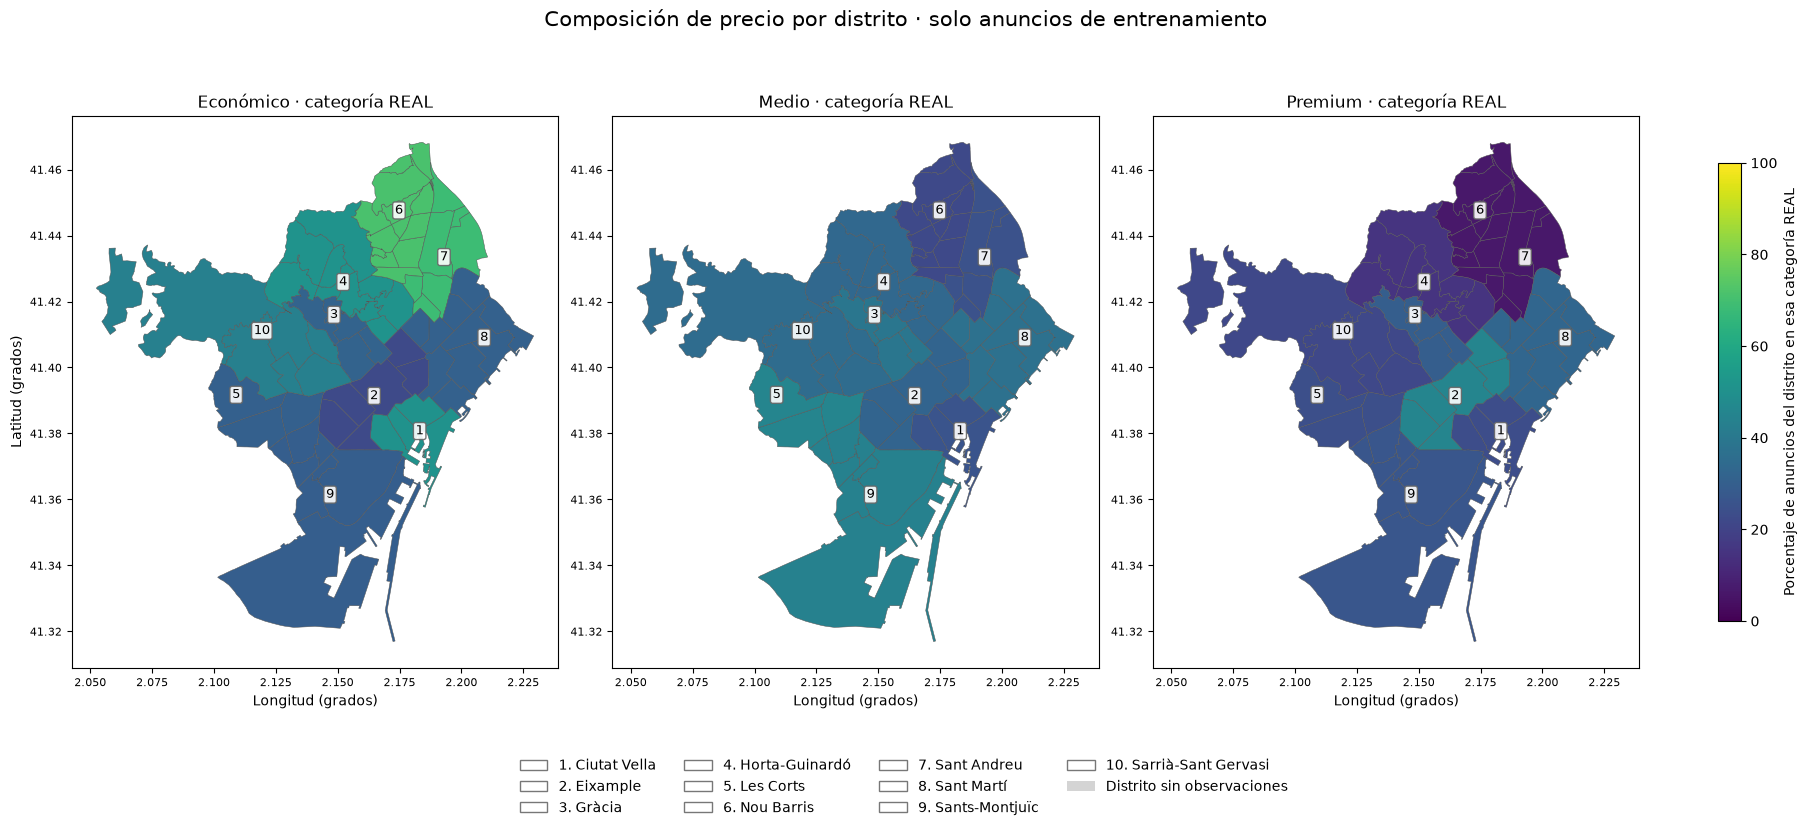

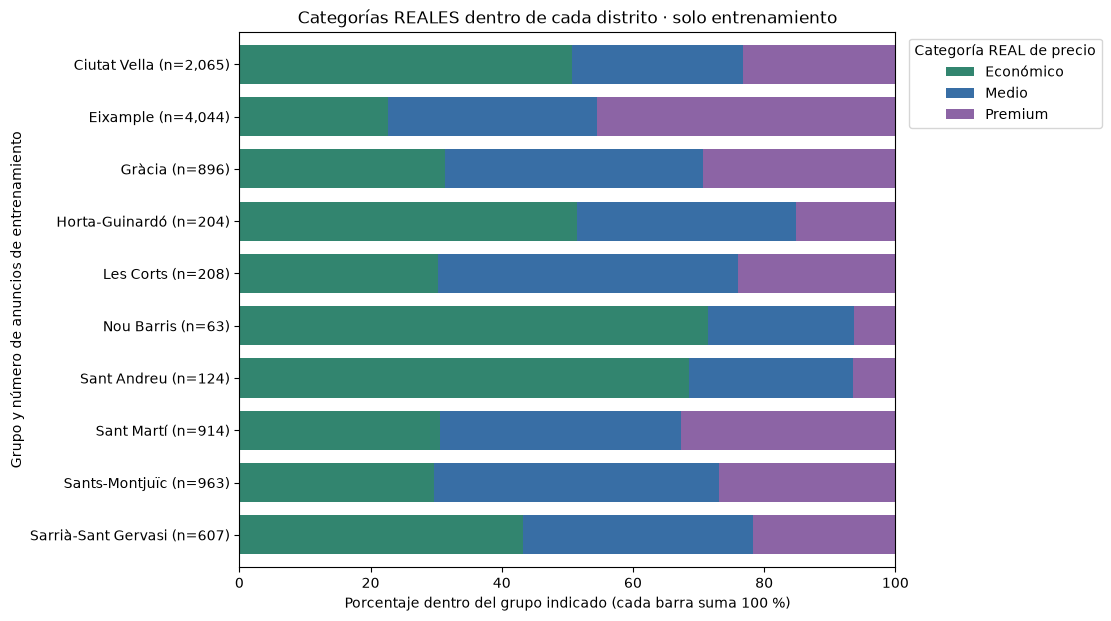

In [4]:
fig = plot_district_maps(geojson, district_summary)
plt.show()
plt.close(fig)
fig = plot_group_bars(district_summary, DISTRICT, title='Categorías REALES dentro de cada distrito · solo entrenamiento')
plt.show()
plt.close(fig)


## 4. Análisis por room_type: modalidad alquilada
`room_type` describe qué se alquila: alojamiento entero, habitación privada, compartida o de hotel. No es `property_type`, que describe el tipo de propiedad. Se usan las categorías originales sin deducirlas unas de otras.

Cada barra suma 100 % de los anuncios de ESA modalidad; la etiqueta `n=` indica cuántos la sostienen. Las etiquetas se traducen para facilitar lectura, pero no se cambian los valores del modelo. Una modalidad pequeña puede mostrar porcentajes extremos a partir de pocos anuncios.

Si las composiciones difieren, existe asociación en este conjunto. No demuestra que cambiar la modalidad cause una subida de precio ni que esa característica por sí sola determine la categoría de un anuncio nuevo.

,room_type,n_listings,count_Económico,pct_Económico,count_Medio,pct_Medio,count_Premium,pct_Premium,small_group,empty_group
0,Entire home/apt,7527,1603,21.30,2839,37.72,3085,40.99,False,False
1,Hotel room,58,2,3.45,30,51.72,26,44.83,False,False
2,Private room,2413,1676,69.46,489,20.27,248,10.28,False,False
3,Shared room,90,85,94.44,1,1.11,4,4.44,False,False


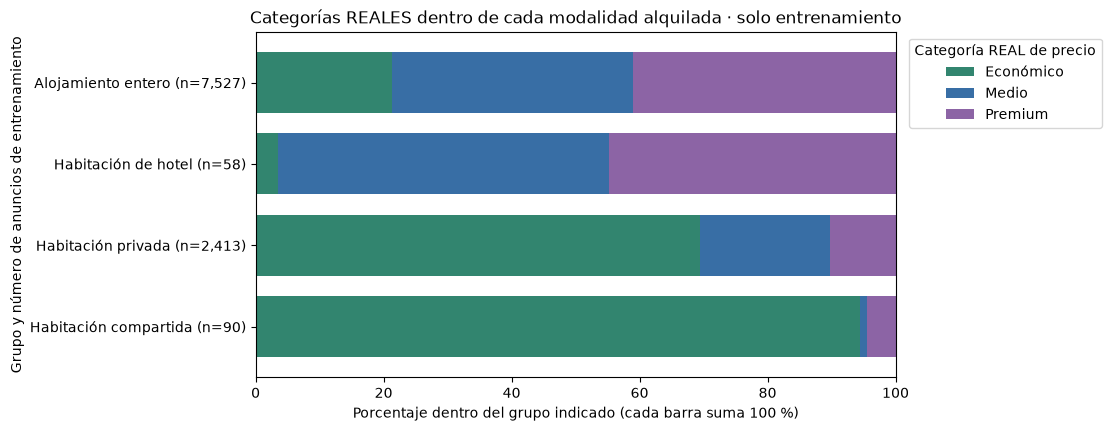

In [5]:
display(room_summary.round(2))
fig = plot_group_bars(room_summary, ROOM, title='Categorías REALES dentro de cada modalidad alquilada · solo entrenamiento')
plt.show()
plt.close(fig)


## 5. Distrito × modalidad: comprobar tamaños y composición
Los distritos pueden tener mezclas distintas de modalidades. Por eso comparamos las categorías REALES dentro de cada combinación distrito × room_type, sin afirmar que hayamos aislado un efecto causal.

Cada casilla muestra porcentaje y número de anuncios DEL GRUPO distrito × modalidad. Las casillas en la misma posición de los tres paneles suman 100 % cuando existe información; las filas dentro de un panel no tienen por qué sumar 100 %. `†` marca n < 30. Gris y «Sin datos, n=0» significan que no observamos esa combinación, no que su precio sea económico ni que la categoría sea imposible.

No se ocultan los grupos pequeños, pero no se usan para afirmar rankings estables. El umbral de 30 es una señal de lectura elegida para esta guía, no una prueba estadística. Las tablas conservan recuentos exactos; el gráfico redondea porcentajes para facilitar lectura.

,neighbourhood_group_cleansed,room_type,n_listings,count_Económico,pct_Económico,count_Medio,pct_Medio,count_Premium,pct_Premium,small_group,empty_group
0,Ciutat Vella,Entire home/apt,1405,644,45.84,373,26.55,388,27.62,False,False
1,Ciutat Vella,Hotel room,21,0,0.00,5,23.81,16,76.19,True,False
2,Ciutat Vella,Private room,635,400,62.99,160,25.20,75,11.81,False,False
3,Ciutat Vella,Shared room,4,3,75.00,1,25.00,0,0.00,True,False
4,Eixample,Entire home/apt,3138,345,10.99,1079,34.38,1714,54.62,False,False
5,Eixample,Hotel room,20,2,10.00,16,80.00,2,10.00,True,False
6,Eixample,Private room,838,520,62.05,197,23.51,121,14.44,False,False
7,Eixample,Shared room,48,47,97.92,0,0.00,1,2.08,False,False
8,Gràcia,Entire home/apt,701,127,18.12,325,46.36,249,35.52,False,False
9,Gràcia,Hotel room,11,0,0.00,6,54.55,5,45.45,True,False


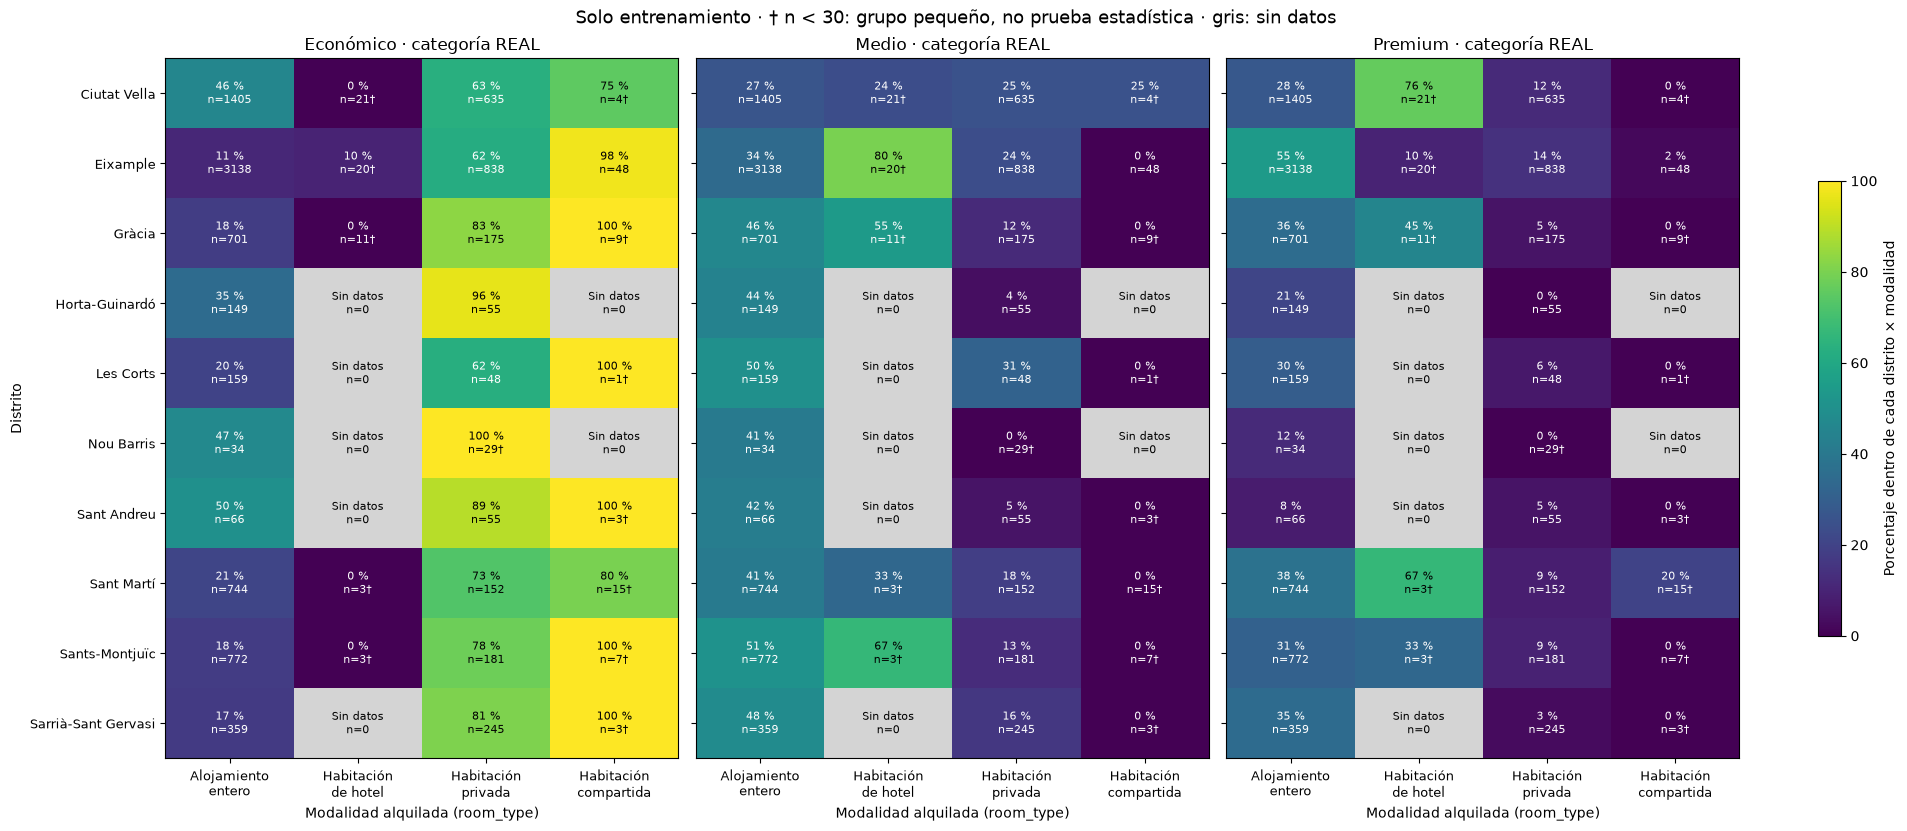

Combinaciones sin observaciones: 7
Combinaciones observadas con menos de 30 anuncios: 13


In [6]:
display(crossed_summary.round(2))
fig = plot_crossed_shares(crossed_summary)
plt.show()
plt.close(fig)
print('Combinaciones sin observaciones:', int(crossed_summary['empty_group'].sum()))
print(f'Combinaciones observadas con menos de {SMALL_GROUP_SIZE} anuncios:', int(crossed_summary['small_group'].sum()))


## 6. Lecturas calculadas, no predicciones
El resumen siguiente se calcula de las tablas anteriores; no contiene valores inventados. Se indican categoría REAL, población del porcentaje y tamaño del grupo. El distrito con mayor porcentaje observado no es necesariamente el de mayor precio mediano o mayor calidad. La comparación descriptiva no mide incertidumbre, no representa reservas ni ingresos y no demuestra cuál será el mejor modelo.

In [7]:
for label in TARGET_LABELS:
    top = district_summary.loc[district_summary[f'pct_{label}'].idxmax()]
    print(f"Mayor proporción observada de categoría REAL {label} dentro de un distrito: {top[DISTRICT]}, {top[f'pct_{label}']:.2f} % de sus {int(top['n_listings'])} anuncios de train.")
for _, group in room_summary.iterrows():
    print(f"{group[ROOM]}: {int(group['n_listings'])} anuncios; categoría REAL Económico {group['pct_Económico']:.2f} %, Medio {group['pct_Medio']:.2f} %, Premium {group['pct_Premium']:.2f} %, dentro de esa modalidad.")
district_sizes = district_summary.set_index(DISTRICT)['n_listings']
print(f'Tamaños por distrito: entre {int(district_sizes.min())} y {int(district_sizes.max())} anuncios; no son muestras equilibradas por zona.')


Mayor proporción observada de categoría REAL Económico dentro de un distrito: Nou Barris, 71.43 % de sus 63 anuncios de train.
Mayor proporción observada de categoría REAL Medio dentro de un distrito: Les Corts, 45.67 % de sus 208 anuncios de train.
Mayor proporción observada de categoría REAL Premium dentro de un distrito: Eixample, 45.45 % de sus 4044 anuncios de train.
Entire home/apt: 7527 anuncios; categoría REAL Económico 21.30 %, Medio 37.72 %, Premium 40.99 %, dentro de esa modalidad.
Hotel room: 58 anuncios; categoría REAL Económico 3.45 %, Medio 51.72 %, Premium 44.83 %, dentro de esa modalidad.
Private room: 2413 anuncios; categoría REAL Económico 69.46 %, Medio 20.27 %, Premium 10.28 %, dentro de esa modalidad.
Shared room: 90 anuncios; categoría REAL Económico 94.44 %, Medio 1.11 %, Premium 4.44 %, dentro de esa modalidad.
Tamaños por distrito: entre 63 y 4044 anuncios; no son muestras equilibradas por zona.


## 7. Evidencia agregada y límites
Se guardan tres CSV descriptivos y un JSON de procedencia. Sus nombres no terminan en `_comparison.csv`, por lo que no se mezclan con las métricas de modelos del lector común. No se exportan identificadores, anuncios, coordenadas individuales ni el GeoJSON.

Limitaciones: snapshot histórico, precios anunciados, captura y limpieza selectivas, reparto aleatorio que no separa anfitriones ni tiempo. Los límites de clases se calculan con train completo; el reparto usa estratificación provisional global, según `docs/decisiones.md`. La composición de esta muestra no demuestra cómo será la de usuarios nuevos. El EDA no justifica modificar variables o modelos sin una comparación posterior acordada.

Los polígonos y nombres públicos proceden de Inside Airbnb, Barcelona, snapshot 2026-09-17, CC BY 4.0. Los datos originales permanecen locales. Reproducción y aceptación: `docs/eda_distritos_room_type.md` y sección de la issue 11 de `docs/pruebas_manuales.md`.

In [8]:
OUT = ROOT / 'docs/results'
OUT.mkdir(parents=True, exist_ok=True)
for name, table in [('districts', district_summary), ('room_types', room_summary), ('district_room_types', crossed_summary)]:
    table.to_csv(OUT / f'eda11_{name}.csv', index=False)
metadata = {
    'issue': 11, 'analysis_set': 'train', 'test_inspected': False, 'model_trained': False,
    'snapshot': '2026-09-17', 'train_rows': len(X_train), 'model_feature_count': len(X_train.columns),
    'class_order': list(TARGET_LABELS), 'class_counts': {label: int((y_train == label).sum()) for label in TARGET_LABELS},
    'thresholds_eur_per_night': thresholds, 'small_group_size': SMALL_GROUP_SIZE,
    'districts': len(district_summary), 'room_types': len(room_summary),
    'crossed_groups': len(crossed_summary),
    'crossed_empty_groups': int(crossed_summary['empty_group'].sum()),
    'crossed_small_groups': int(crossed_summary['small_group'].sum()),
    'coverage': coverage, 'geometry_joined_to_model': False,
    'raw_sha256': hashlib.sha256(RAW_DATA_PATH.read_bytes()).hexdigest(),
    'geojson_sha256': hashlib.sha256(GEO_PATH.read_bytes()).hexdigest(),
    'code_commit': subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip(),
    'source_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest() for name in
        ['src/cleaning.py', 'src/preprocessing.py', 'src/eda_map.py']},
    'python': platform.python_version(),
    'versions': {name: importlib.metadata.version(name) for name in ['pandas', 'numpy', 'matplotlib', 'scikit-learn']},
}
(OUT / 'eda11_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2) + '\n')
print('Verificación final correcta: solo agregados de train; sin modelos, sin test y sin unión geométrica al modelo.')


Verificación final correcta: solo agregados de train; sin modelos, sin test y sin unión geométrica al modelo.
